# TP 2 Extraction d'informations

## Imports et stopwords

In [1]:
import os
import yake
from collections import Counter
from wordcloud import WordCloud
import os
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from IPython.display import Image
from collections import defaultdict
import spacy
from spacy.lang.fr.examples import sentences
from textblob import Blobber
from textblob_fr import PatternTagger, PatternAnalyzer

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/alexiawaucquez/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!

A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/Users/alexiawaucquez/tac/.venv/lib/python3.11/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/Users/alexiawaucquez/tac/.venv/lib/python3.11/site-packages/traitlets/config/application.py", line 1080, in launch_inst

## Choix d'une année

In [2]:
# Choisir une année
year = 1969

In [13]:
# Lister les fichiers de cette année
data_path = './txt'
txt_path = './txt'
txts = [f for f in os.listdir(txt_path) if os.path.isfile(os.path.join(txt_path, f)) and str(year) in f]
len(txts)

100

In [9]:
# Stocker le contenu de ces fichiers dans une liste
content_list = []
for txt in txts:
    with open(os.path.join(txt_path, txt), 'r', encoding='utf-8') as f:
        content_list.append(f.read())

In [10]:
# Ecrire tout le contenu dans un fichier temporaire
temp_path = './tmp'
if not os.path.exists(temp_path):
    os.mkdir(temp_path)
with open(os.path.join(temp_path, f'{year}.txt'), 'w', encoding='utf-8') as f:
    f.write(' '.join(content_list))

## Extraction de mots clefs

In [11]:
# Instantier l'extracteur de mots clés
kw_extractor = yake.KeywordExtractor(lan="fr", top=50)
kw_extractor

In [14]:
# Lister les Fichiers
data_path = "./tmp"
files = [f for f in os.listdir(data_path) if f.endswith('.txt')]

In [15]:
for f in sorted(files):
    text = open(os.path.join(data_path, f), 'r', encoding="utf-8").read()
    keywords = kw_extractor.extract_keywords(text)
    kept = []
    for kw, score in keywords:
        words = kw.split()
        if len(words) == 2:
            kept.append(kw)
    print(f"{f} mentions these keywords: {', '.join(kept)}...")

1969.txt mentions these keywords: Agence Rossel, Bruxelles Tél, l’Agence Rossel, Bruxelles dem, BRUXELLES DEMANDE, BRUXELLES engage, Bar dem, Dames dem, BRUXELLES CENTRE, Ecrire Agence, bel app, Bruxelles Bruxelles, Faire offre, rue Royale...


## Enrichissement de la liste de stopwords et génération du nuage de mots

In [24]:
# Stopwords (Idem que dans s1)
sw = stopwords.words("french")
sw += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
       "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
       "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
       "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
       "van", "het", "autre", "jusqu", "ville", "rossel", "dem", "l", "tel", "tél", 
       "écrire", "etc", "ets", "app", "très"]
sw = set(sw)


In [26]:
def clean_text(year, folder=None):
    if folder is None:
        input_path = f"{year}.txt"
        output_path = f"{year}_clean.txt"
    else:
        input_path = f"{folder}/{year}.txt"
        output_path = f"{folder}/{year}_clean.txt"
    output = open(output_path, "w", encoding='utf-8')
    with open(input_path, 'r', encoding='utf-8') as f:
        text = f.read()
        words = nltk.wordpunct_tokenize(text)
        kept = [w.upper() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in sw]
        kept_string = " ".join(kept)
        output.write(kept_string)
    return f'Output has been written in {output_path}!'

In [27]:
clean_text(year, folder=temp_path)

'Output has been written in ./tmp/1969_clean.txt!'

In [28]:
# Vérifier le résultat
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()

after[:500]

'VANDEN BOUDE CHAUSSÉE MONS ANDERLECTIT BRUXELLES DEMANDENT ELECTRICIENS QUALIFIES INSTALLATION BASSE TENSION PLOMBIERS SACHANT CONDUIRE POSSIBLE MAGASINIERS DÉPÔT RUE ROUE PLACE STABLE AVENIR FIRME CONTINUELLE EXPANSION BONNE RÉMUNÉRATION PRIÈRE ADRESSER SERVICE PERSONNEL DOCT ZAMENHOF ANDERLECHT VEEWEYDE POSTE AUTOBUS TRAMS VANDERBORGHT FRÈRES ENGAGENT AIDES MAGASINIERS PRÉPARATION COMMANDES BONS SALAIRES SEMAINES JOURS PENSION EXTRA LÉGALE GRATUITE PRÉSENTER SERVICE PERSONNEL RUE FOSSÉ LOUPS B'

In [29]:
frequencies = Counter(after.split())
print(frequencies.most_common(10))

[('BRUXELLES', 1395), ('RUE', 1168), ('BRUX', 677), ('ANS', 637), ('GAR', 582), ('HEURES', 486), ('PRÉS', 466), ('CUIS', 465), ('PRIX', 451), ('ECRIRE', 434)]


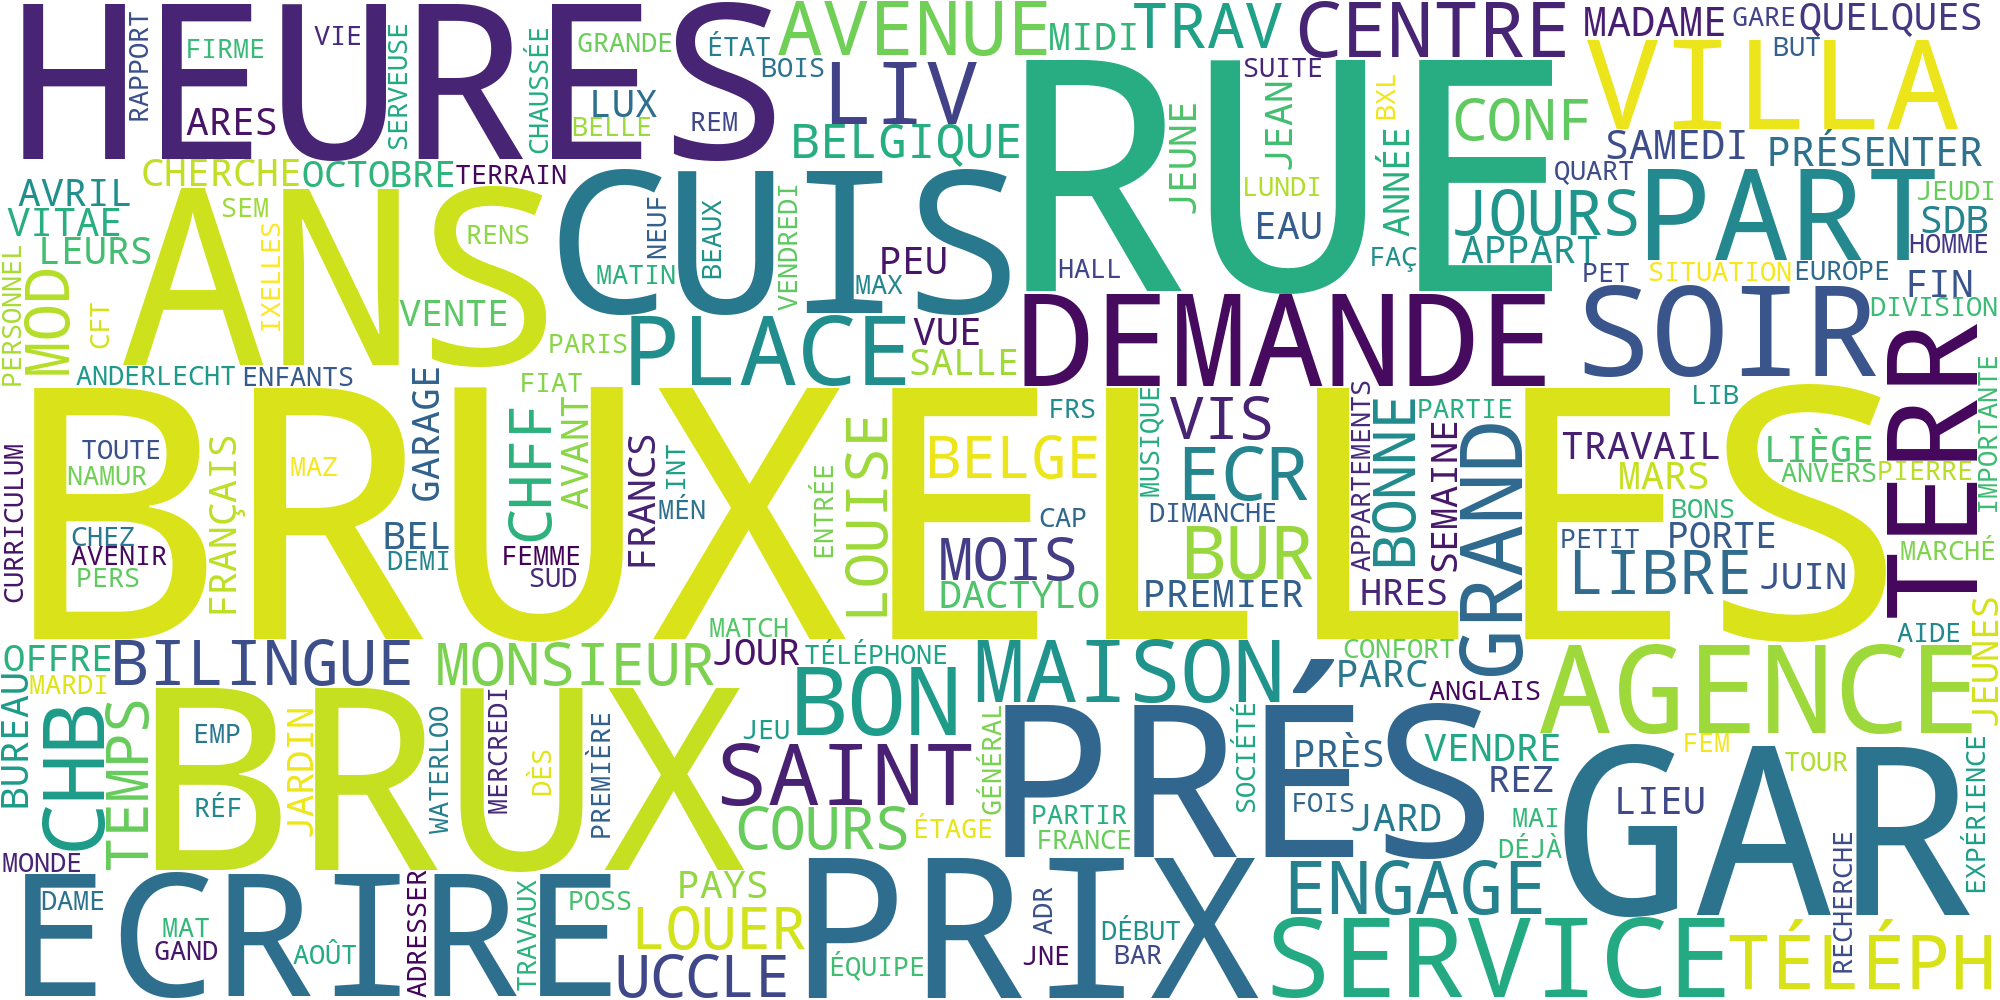

In [30]:
cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(frequencies)
cloud.to_file(os.path.join(temp_path, f"{year}.png"))
Image(filename=os.path.join(temp_path, f"{year}.png"))

## Entités principales pertinentes